# 02 · EDA — AccessGuard AI

**Hito H1 · Clase 2.** Exploración de `Data/train.csv` (con etiqueta) y `Data/test.csv` (sin etiqueta).
Regla de oro: *el EDA no es hacer gráficos; es descubrir qué decisiones hay que tomar antes de modelar.* Cada hallazgo termina
en una decisión escrita, con cifra y motivo (sección 11). Hipótesis previas y plan de medición: `especificaciones/02-eda.md`.

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path[:0] = [str(ROOT), str(ROOT / "src")]   # permite importar config/ y src/accessguard

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import settings as S

pd.set_option("display.max_columns", 30, "display.width", 140)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold", "axes.titlesize": 11,
})
BLUE, ORANGE, GRAY = "#2A6FBB", "#D9622B", "#8A8F98"   # aprobado / denegado / neutro

from accessguard.stats import cramers_matrix

train = pd.read_csv(S.TRAIN_PATH)
test = pd.read_csv(S.TEST_PATH)
FEATS = S.FEATURES

## 1. Estructura: filas, columnas y tipos

In [2]:
print(f"train: {train.shape[0]:,} x {train.shape[1]}   |   test: {test.shape[0]:,} x {test.shape[1]}")
print("Columnas solo en train:", sorted(set(train.columns) - set(test.columns)))
print("Columnas solo en test :", sorted(set(test.columns) - set(train.columns)))
print("\nTipos en train:\n", train.dtypes.value_counts().to_string())
print("\nMismas columnas de entrada en train y test:", set(FEATS) <= set(train.columns) and set(FEATS) <= set(test.columns))
train.describe().T[["min", "50%", "max"]].round(0)

train: 32,769 x 10   |   test: 58,921 x 10
Columnas solo en train: ['ACTION']
Columnas solo en test : ['id']

Tipos en train:
 int64    10

Mismas columnas de entrada en train y test: True


,min,50%,max
ACTION,0.0,1.0,1.0
RESOURCE,0.0,35376.0,312153.0
MGR_ID,25.0,13545.0,311696.0
ROLE_ROLLUP_1,4292.0,117961.0,311178.0
ROLE_ROLLUP_2,23779.0,118300.0,286791.0
ROLE_DEPTNAME,4674.0,118921.0,286792.0
ROLE_TITLE,117879.0,118568.0,311867.0
ROLE_FAMILY_DESC,4673.0,128696.0,311867.0
ROLE_FAMILY,3130.0,119006.0,308574.0
ROLE_CODE,117880.0,118570.0,270691.0


**Lectura.** Las 9 variables de entrada son **enteros, pero no son cantidades**: son *códigos anónimos* de categorías
(un recurso, un gerente, un título de rol). Tratarlos como números sería un error (el recurso 40000 no es "el doble" del 20000).
`test.csv` agrega solo la columna `id` y **no trae `ACTION`**.

## 2. Calidad: vacíos, duplicados, centinelas e identificadores

In [3]:
quality = pd.DataFrame({
    "vacíos train": train[FEATS].isna().sum(),
    "vacíos test": test[FEATS].isna().sum(),
    "mínimo train": train[FEATS].min(),
    "filas con valor ≤ 0 en train": (train[FEATS] <= 0).sum(),
    "filas con valor ≤ 0 en test": (test[FEATS] <= 0).sum(),
})
display(quality)
print("Filas duplicadas exactas  train:", train.duplicated().sum(), "| test (sin id):", test.drop(columns="id").duplicated().sum())
print("Filas con las 9 variables repetidas pero ACTION distinto (conflictos):",
      (train.groupby(FEATS)[S.TARGET].nunique() > 1).sum())
print("`id` de test único y consecutivo:", test["id"].is_unique and test["id"].is_monotonic_increasing)

,vacíos train,vacíos test,mínimo train,filas con valor ≤ 0 en train,filas con valor ≤ 0 en test
RESOURCE,0,0,0,13,25
MGR_ID,0,0,25,0,0
ROLE_ROLLUP_1,0,0,4292,0,0
ROLE_ROLLUP_2,0,0,23779,0,0
ROLE_DEPTNAME,0,0,4674,0,0
ROLE_TITLE,0,0,117879,0,0
ROLE_FAMILY_DESC,0,0,4673,0,0
ROLE_FAMILY,0,0,3130,0,0
ROLE_CODE,0,0,117880,0,0


Filas duplicadas exactas  train: 0 | test (sin id): 0
Filas con las 9 variables repetidas pero ACTION distinto (conflictos): 0
`id` de test único y consecutivo: True


**Lectura.** No hay vacíos, ni duplicados, ni centinelas evidentes (`-1`, `0`, `9999`): el dataset ya viene limpio en ese sentido.
Un vacío, de existir, **significaría** "el atributo no se registró" (no "no aplica"). Aun así el pipeline de producción debe
tolerar vacíos (una solicitud nueva puede traerlos), por eso se incluye un imputador de seguridad en `03`.
Único valor sospechoso: `RESOURCE = 0` (13 filas en train, 25 en test; 92 % aprobadas, 9 gerentes distintos). Podría ser un código real o un
"recurso sin asignar"; con 13 filas no hay forma de saberlo con los datos. Se conserva como una categoría más (la codificación lo trata como cualquier otro código) y se pregunta al dueño del dato.

## 3. Variable respuesta (`ACTION`)

In [4]:
vc = train[S.TARGET].value_counts()
print(f"Aprobadas={vc[1]:,} ({vc[1]/len(train):.2%})  Denegadas={vc[0]:,} ({vc[0]/len(train):.2%})  → desbalance {vc[1]/vc[0]:.1f} : 1")
print(f"Exactitud de la regla trivial 'aprobar siempre': {vc[1]/len(train):.2%}")
lab_per_mgr = train.groupby(S.GROUP_COL)[S.TARGET].agg(["size", "mean"])
print(f"\nGerentes con al menos una denegación: {(lab_per_mgr['mean'] < 1).mean():.1%}")
print(f"Gerentes con TODAS sus solicitudes denegadas: {(lab_per_mgr['mean'] == 0).sum()}")

Aprobadas=30,872 (94.21%)  Denegadas=1,897 (5.79%)  → desbalance 16.3 : 1
Exactitud de la regla trivial 'aprobar siempre': 94.21%

Gerentes con al menos una denegación: 19.2%
Gerentes con TODAS sus solicitudes denegadas: 68


**Lectura.** Desbalance de ~16:1. Predecir siempre "aprobar" da ~94 % de exactitud: **la exactitud no sirve** (decisión de métrica del notebook 01).
La clase minoritaria (denegar) es justo la que más cuesta equivocar.

## 4. Cardinalidad y cobertura entre `train` y `test`

,categorías train,categorías test,categorías de test no vistas en train,% filas test con categoría nueva,% filas train con categoría que aparece 1 sola vez
columna,,,,,
RESOURCE,7518,4971,0,0.00,11.49
MGR_ID,4243,4689,670,2.76,2.58
ROLE_ROLLUP_1,128,126,2,0.01,0.03
ROLE_ROLLUP_2,177,177,6,0.02,0.05
ROLE_DEPTNAME,449,466,27,0.11,0.07
ROLE_TITLE,343,351,18,0.05,0.10
ROLE_FAMILY_DESC,2358,2749,593,2.12,1.96
ROLE_FAMILY,67,68,1,0.00,0.00
ROLE_CODE,343,351,18,0.05,0.10


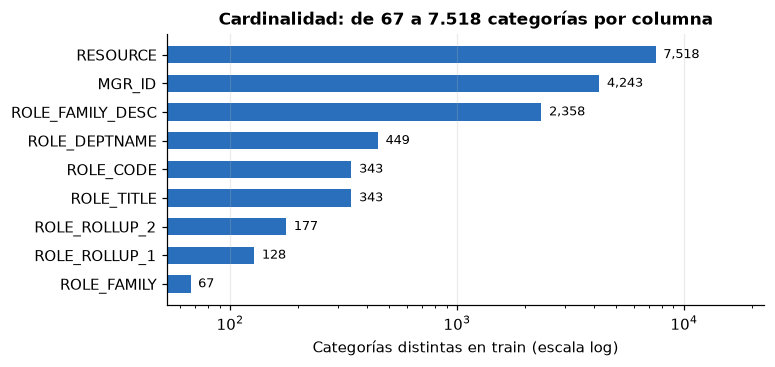

In [5]:
rows = []
for c in FEATS:
    seen = set(train[c])
    rows.append({
        "columna": c,
        "categorías train": train[c].nunique(),
        "categorías test": test[c].nunique(),
        "categorías de test no vistas en train": len(set(test[c]) - seen),
        "% filas test con categoría nueva": (~test[c].isin(seen)).mean() * 100,
        "% filas train con categoría que aparece 1 sola vez": (train[c].map(train[c].value_counts()) == 1).mean() * 100,
    })
card = pd.DataFrame(rows).set_index("columna")
display(card.round(2))

fig, ax = plt.subplots(figsize=(7, 3.2))
order = card["categorías train"].sort_values()
ax.barh(order.index, order.values, color=BLUE, height=0.6)
ax.set_xscale("log"); ax.grid(axis="y", visible=False)
for y_, v in enumerate(order.values):
    ax.text(v * 1.08, y_, f"{v:,}", va="center", fontsize=8.5)
ax.set_xlim(right=order.max() * 3); ax.set_xlabel("Categorías distintas en train (escala log)")
ax.set_title("Cardinalidad: de 67 a 7.518 categorías por columna")
plt.show()

**Lectura.** Hay tres columnas de **alta cardinalidad** (`RESOURCE`, `MGR_ID`, `ROLE_FAMILY_DESC`: miles de categorías) y seis de
cardinalidad media/baja. En `test.csv` aparecen **gerentes y familias de rol que el modelo nunca vio**, y el porcentaje de filas afectadas
es pequeño pero no cero: el modelo debe saber qué hacer con lo desconocido. Un *one-hot* de las tres columnas grandes crearía miles de columnas casi vacías.

## 5. Entidades que se repiten (unidad de análisis y partición)

Gerentes distintos: 4,243 para 32,769 filas → 7.7 solicitudes por gerente (mediana 4, máx 152)
Recursos distintos: 7,518 → 4.4 por recurso (mediana 1, máx 839)
% de filas de gerentes con ≥ 10 solicitudes: 66.7%

Partición por FILA (20 % reserva): 96.2% de la reserva comparte gerente con entrenamiento
En test.csv real: 97.2% de las filas tiene un gerente conocido de train


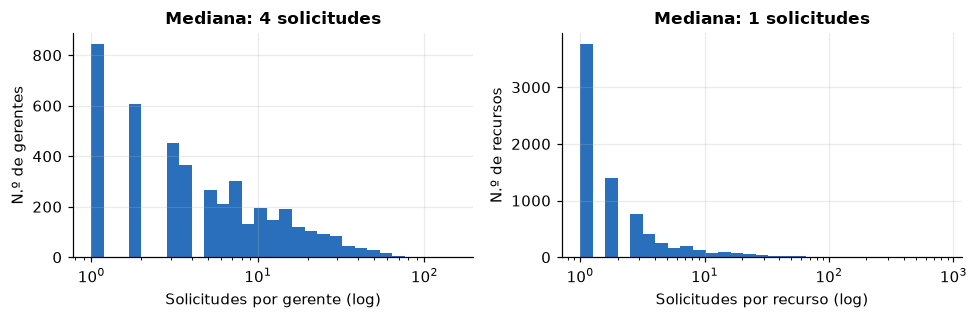

In [6]:
per_mgr = train.groupby("MGR_ID").size()
per_res = train.groupby("RESOURCE").size()
print(f"Gerentes distintos: {per_mgr.size:,} para {len(train):,} filas → {per_mgr.mean():.1f} solicitudes por gerente (mediana {per_mgr.median():.0f}, máx {per_mgr.max()})")
print(f"Recursos distintos: {per_res.size:,} → {per_res.mean():.1f} por recurso (mediana {per_res.median():.0f}, máx {per_res.max()})")
print(f"% de filas de gerentes con ≥ 10 solicitudes: {(train['MGR_ID'].map(per_mgr) >= 10).mean():.1%}")

# Si partiéramos por fila, ¿cuántas filas de la reserva tendrían un gerente ya visto en entrenamiento?
rng = np.random.default_rng(S.SEED)
mask = rng.random(len(train)) < 0.2
seen_share = train.loc[mask, "MGR_ID"].isin(train.loc[~mask, "MGR_ID"]).mean()
print(f"\nPartición por FILA (20 % reserva): {seen_share:.1%} de la reserva comparte gerente con entrenamiento")
print(f"En test.csv real: {test['MGR_ID'].isin(set(train['MGR_ID'])).mean():.1%} de las filas tiene un gerente conocido de train")

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, s_, nm in zip(axes, [per_mgr, per_res], ["gerente", "recurso"]):
    ax.hist(s_, bins=np.logspace(0, np.log10(s_.max() + 1), 30), color=BLUE)
    ax.set_xscale("log"); ax.set_xlabel(f"Solicitudes por {nm} (log)"); ax.set_ylabel(f"N.º de {nm}s")
    ax.set_title(f"Mediana: {s_.median():.0f} solicitudes")
plt.tight_layout(); plt.show()

**Lectura.** Una fila es una **solicitud**, pero los gerentes y recursos se repiten muchísimo (cola larga: muchos con 1–3 solicitudes, unos pocos con cientos).
Un mismo gerente tiende a decidir de forma parecida. Si se parte **por fila**, la reserva comparte gerentes con el entrenamiento y el modelo
"recuerda" al gerente en vez de aprender un patrón general → métricas infladas (se mide en `03`). La partición correcta es **por `MGR_ID`**.
`test.csv` sí contiene mayoritariamente gerentes ya vistos; por eso la partición por gerente es una evaluación **conservadora** (pesimista), y se documenta como tal.

## 6. ¿Dónde se concentran las denegaciones?

Por frecuencia del RECURSO:
           filas  tasa denegación
RESOURCE                        
1          3766            0.071
2-3        5068            0.068
4-10       6507            0.058
11-30      5481            0.056
31-100     5107            0.057
>100       6840            0.045

Por frecuencia del GERENTE:
         filas  tasa denegación
MGR_ID                        
1         845            0.054
2-3      2570            0.056
4-10     8588            0.064
11-30   13888            0.059
31-100   6726            0.050
>100      152            0.033


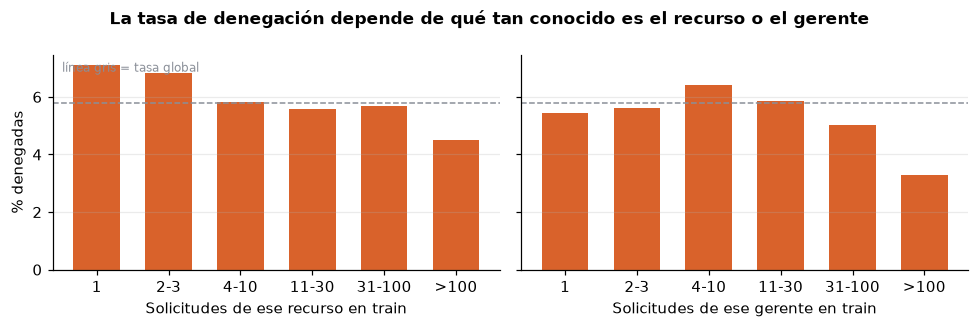

In [7]:
# Tasa de denegación según qué tan frecuente es el recurso / el gerente (en train)
def bucket(s_):
    return pd.cut(s_, [0, 1, 3, 10, 30, 100, 10_000], labels=["1", "2-3", "4-10", "11-30", "31-100", ">100"])

res_n = train["RESOURCE"].map(per_res)
mgr_n = train["MGR_ID"].map(per_mgr)
t_res = train.groupby(bucket(res_n), observed=True)[S.TARGET].agg(["size", lambda s_: 1 - s_.mean()]).set_axis(["filas", "tasa denegación"], axis=1)
t_mgr = train.groupby(bucket(mgr_n), observed=True)[S.TARGET].agg(["size", lambda s_: 1 - s_.mean()]).set_axis(["filas", "tasa denegación"], axis=1)
print("Por frecuencia del RECURSO:\n", t_res.round(3).to_string())
print("\nPor frecuencia del GERENTE:\n", t_mgr.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for ax, t_, nm in zip(axes, [t_res, t_mgr], ["recurso", "gerente"]):
    ax.bar(t_.index.astype(str), t_["tasa denegación"] * 100, color=ORANGE, width=0.65)
    ax.axhline((1 - train[S.TARGET].mean()) * 100, color=GRAY, ls="--", lw=1)
    ax.set_xlabel(f"Solicitudes de ese {nm} en train"); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% denegadas"); axes[0].text(0.02, 0.92, "línea gris = tasa global", transform=axes[0].transAxes, fontsize=8, color=GRAY)
fig.suptitle("La tasa de denegación depende de qué tan conocido es el recurso o el gerente", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

**Lectura.** Para el **recurso** la relación es clara y monótona: los recursos que casi nadie pide (1 solicitud) se deniegan ~7,1 %, y los muy pedidos
(>100) ~4,5 %. Para el **gerente** no es monótona (el 3,3 % del grupo >100 son solo 152 filas), así que su señal de frecuencia es débil.
Se agregan **variables de frecuencia** como *hipótesis*, y se comprueba su aporte con ablación en `03`. Una categoría nunca vista se codifica con frecuencia 0 ("sin historial").

## 7. Jerarquía de roles: ¿qué columnas son redundantes?

In [8]:
role_cols = ["ROLE_ROLLUP_1", "ROLE_ROLLUP_2", "ROLE_DEPTNAME", "ROLE_TITLE", "ROLE_FAMILY_DESC", "ROLE_FAMILY", "ROLE_CODE"]

def determines(a, b, df=train):
    # fracción de categorías de `a` que tienen un único valor de `b`  (1.0 → `a` determina a `b`)
    return (df.groupby(a)[b].nunique() == 1).mean()

fd = pd.DataFrame({b: {a: determines(a, b) for a in role_cols} for b in role_cols})
fd.index.name = "A (fila) determina B (columna)"
display(fd.round(3))
print("ROLE_TITLE ↔ ROLE_CODE uno a uno en train:", determines("ROLE_TITLE", "ROLE_CODE") == 1 and determines("ROLE_CODE", "ROLE_TITLE") == 1)
print("ROLE_TITLE ↔ ROLE_CODE uno a uno en test :", determines("ROLE_TITLE", "ROLE_CODE", test) == 1 and determines("ROLE_CODE", "ROLE_TITLE", test) == 1)

,ROLE_ROLLUP_1,ROLE_ROLLUP_2,ROLE_DEPTNAME,ROLE_TITLE,ROLE_FAMILY_DESC,ROLE_FAMILY,ROLE_CODE
A (fila) determina B (columna),,,,,,,
ROLE_ROLLUP_1,1.000,0.750,0.188,0.094,0.102,0.117,0.094
ROLE_ROLLUP_2,0.983,1.000,0.243,0.147,0.141,0.203,0.147
ROLE_DEPTNAME,0.477,0.392,1.000,0.147,0.127,0.269,0.147
ROLE_TITLE,0.394,0.289,0.300,1.000,0.227,1.000,1.000
ROLE_FAMILY_DESC,0.860,0.804,0.796,0.840,1.000,0.928,0.840
ROLE_FAMILY,0.239,0.179,0.179,0.194,0.119,1.000,0.194
ROLE_CODE,0.394,0.289,0.300,1.000,0.227,1.000,1.000


ROLE_TITLE ↔ ROLE_CODE uno a uno en train: True
ROLE_TITLE ↔ ROLE_CODE uno a uno en test : True


**Lectura.** `ROLE_TITLE` y `ROLE_CODE` son **la misma información con otro nombre** (343 categorías, correspondencia exacta 1 a 1 en train y en test): una de las dos sobra.
Además los roles forman una **jerarquía**: p. ej. `ROLE_TITLE` determina `ROLE_FAMILY` (100 %) y `ROLE_ROLLUP_2` determina casi por completo a `ROLE_ROLLUP_1` (98,3 %; al revés solo 75 %). Es decir, hay variables que "deberían ser estables" dentro de un rol y lo son:
no hay inconsistencias que reparar, pero sí **redundancia** que cuidar (inflaría la importancia de una información repetida).

## 8. Asociación entre variables y con el objetivo (V de Cramér)

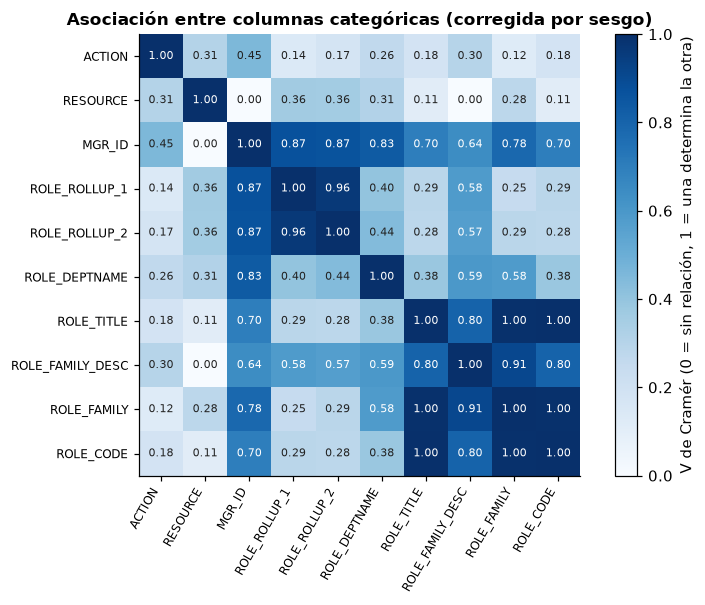

Asociación con ACTION (de mayor a menor):
MGR_ID              0.454
RESOURCE            0.306
ROLE_FAMILY_DESC    0.299
ROLE_DEPTNAME       0.264
ROLE_TITLE          0.182
ROLE_CODE           0.182
ROLE_ROLLUP_2       0.175
ROLE_ROLLUP_1       0.139
ROLE_FAMILY         0.122


In [9]:
cv = cramers_matrix(train, [S.TARGET] + FEATS)
fig, ax = plt.subplots(figsize=(7.4, 5.6))
im = ax.imshow(cv.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(cv))); ax.set_xticklabels(cv.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(cv))); ax.set_yticklabels(cv.index, fontsize=8); ax.grid(False)
for i in range(len(cv)):
    for j in range(len(cv)):
        v = cv.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.55 else "#222")
plt.colorbar(im, fraction=0.04, label="V de Cramér (0 = sin relación, 1 = una determina la otra)")
ax.set_title("Asociación entre columnas categóricas (corregida por sesgo)")
plt.tight_layout(); plt.show()

print("Asociación con ACTION (de mayor a menor):")
print(cv[S.TARGET].drop(S.TARGET).sort_values(ascending=False).round(3).to_string())

**Lectura.** Con variables categóricas, la correlación de Pearson no aplica; se usa **V de Cramér**. Tres hechos:
(1) `ROLE_TITLE`, `ROLE_CODE` y `ROLE_FAMILY` forman un bloque casi perfectamente asociado (≈ 1,00);
(2) `MGR_ID` es el que más se asocia con `ACTION` y a la vez con casi todos los atributos del rol: **identifica a un equipo**;
(3) ninguna columna "explica" `ACTION` por sí sola con valores cercanos a 1 → no hay una fuga evidente tipo "columna que es la respuesta".
Cuidado: con miles de categorías, V puede sobrestimar el vínculo; lo confirmamos con modelos en `03`.

## 9. Deriva entre `train` y `test`

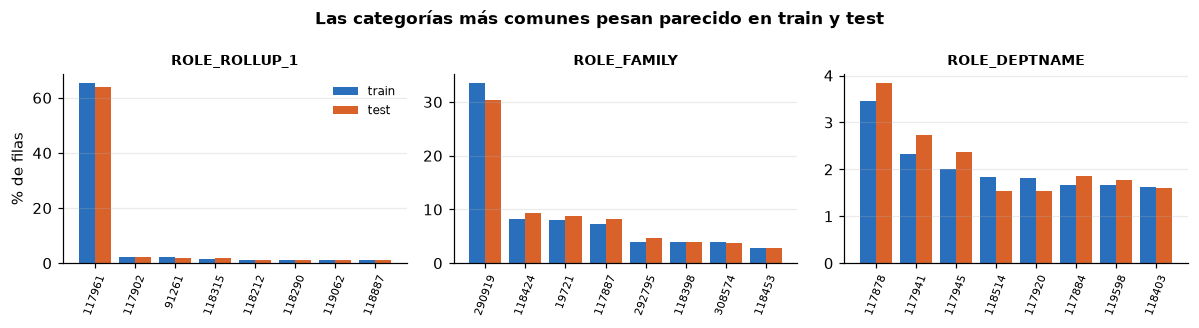

MGR_ID              0.280
ROLE_FAMILY_DESC    0.181
RESOURCE            0.092
ROLE_DEPTNAME       0.033
ROLE_TITLE          0.027
ROLE_CODE           0.027
ROLE_FAMILY         0.013
ROLE_ROLLUP_2       0.013
ROLE_ROLLUP_1       0.008

Referencia: PSI < 0,1 estable · 0,1–0,25 cambio moderado · > 0,25 cambio fuerte


In [10]:
# Frecuencia relativa de las categorías más comunes del train, comparada con test
cols_show = ["ROLE_ROLLUP_1", "ROLE_FAMILY", "ROLE_DEPTNAME"]
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, c in zip(axes, cols_show):
    top = train[c].value_counts(normalize=True).head(8)
    tst = test[c].value_counts(normalize=True).reindex(top.index).fillna(0)
    x = np.arange(len(top))
    ax.bar(x - 0.2, top.values * 100, 0.4, color=BLUE, label="train")
    ax.bar(x + 0.2, tst.values * 100, 0.4, color=ORANGE, label="test")
    ax.set_xticks(x); ax.set_xticklabels(top.index.astype(str), rotation=70, fontsize=7); ax.set_title(c, fontsize=9)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% de filas"); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Las categorías más comunes pesan parecido en train y test", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

# Distancia entre distribuciones (PSI) por columna sobre las categorías de train + 'nueva'
def psi(a, b, eps=1e-4):
    cats = a.value_counts(normalize=True)
    bb = b.map(lambda v: v if v in cats.index else "__nueva__").value_counts(normalize=True)
    aa = pd.concat([cats, pd.Series({"__nueva__": 0.0})])
    bb = bb.reindex(aa.index).fillna(0)
    aa, bb = aa.clip(eps), bb.clip(eps)
    return float(((bb - aa) * np.log(bb / aa)).sum())

psi_tbl = pd.Series({c: psi(train[c], test[c]) for c in FEATS}, name="PSI train→test").sort_values(ascending=False)
print(psi_tbl.round(3).to_string())
print("\nReferencia: PSI < 0,1 estable · 0,1–0,25 cambio moderado · > 0,25 cambio fuerte")

**Lectura.** `MGR_ID` (PSI ≈ 0,28, cambio fuerte), `ROLE_FAMILY_DESC` (≈ 0,18, moderado) y `RESOURCE` (≈ 0,09) cambian entre `train` y `test`; las columnas de rol
de baja cardinalidad son estables. Es esperable: son las de miles de categorías, donde las raras (1–2 filas) mueven mucho el PSI, así que **interprétese con cautela**.
Conclusión práctica: `test.csv` no es una réplica de `train.csv`; la validación debe ser conservadora y el modelo robusto a categorías nuevas.

## 10. Fuga de información y datos personales

- **Datos personales:** ninguno. Solo hay códigos numéricos anónimos (no nombres, correos ni documentos). No se elimina ninguna columna por este motivo.
- **Columnas posteriores a la decisión:** ninguna de las 9 variables describe el resultado; todas se conocen **al momento de la solicitud** (rol, gerente, recurso).
- **Fuga por partición (el riesgo real):** `MGR_ID`/`RESOURCE` repetidos entre `train` y reserva. Se mitiga partiendo por gerente y calculando todas las codificaciones **dentro del Pipeline**, solo con el entrenamiento.
- **Fuga por la codificación del objetivo:** la codificación por tasa de aprobación (*target encoding*) usa la etiqueta; se ajusta con validación cruzada interna (`cv=5`) para que cada fila no vea su propia etiqueta.
- **Etiqueta = decisión humana:** `ACTION` refleja el criterio de los revisores; si ellos fueron inconsistentes, es "ruido de etiqueta" que ningún preprocesamiento arregla.

## 11. Tabla de decisiones: hallazgo → decisión → motivo

| # | Hallazgo (con cifra) | Decisión | Motivo | Se implementa en |
|---|---|---|---|---|
| 1 | 9 columnas de entrada son enteros que **identifican categorías**; 0 vacíos y 0 duplicados en train y test | Tratar todas como **categóricas** (texto), no escalarlas como cantidades; mantener un imputador de seguridad | El tamaño de un código no significa nada; en producción pueden llegar vacíos | `features.to_str`, `build_preprocessor` |
| 2 | `ACTION`: 94,2 % aprobadas / 5,8 % denegadas (≈ 16:1) | Métrica principal = **costo esperado**; reportar ROC-AUC y PR-AUC de *denegar*; **estratificar** las particiones | Accuracy trivial = 94,2 %; la clase rara es la costosa | `split_by_group` (estratificado) |
| 3 | `MGR_ID`: 4.243 gerentes para 32.769 filas (≈ 7,7 solicitudes por gerente, máx. 152); `RESOURCE` igual | Partir train/validación **por `MGR_ID`** (`StratifiedGroupKFold`), reserva cerrada | Evitar fuga: un gerente decide de forma correlacionada | `split_by_group` + `test_split.py` |
| 4 | `ROLE_TITLE` ↔ `ROLE_CODE`: correspondencia 1 a 1 (343 = 343) en train y test | **Eliminar `ROLE_CODE`** | Información duplicada; no aporta y complica la interpretación | `drop_redundant` + `test_cleaning.py` |
| 5 | Alta cardinalidad: `RESOURCE` 7.518, `MGR_ID` 4.243, `ROLE_FAMILY_DESC` 2.358 categorías; en test hay 670 gerentes y 593 familias-desc. nuevos (≈ 2,8 % y 2,1 % de las filas) | **No usar one-hot** en esas 3: *target encoding* con validación cruzada + frecuencia; las de baja cardinalidad con one-hot agrupando categorías raras (`min_frequency`) | One-hot crearía >14.000 columnas casi vacías; lo desconocido debe tener un valor por defecto sensato | `build_preprocessor` + `test_features.py` |
| 6 | La tasa de denegación baja de 7,1 % (recurso con 1 solicitud) a 4,5 % (>100); en gerentes la relación no es monótona | Agregar **variables de frecuencia** (`log(1+conteo)` en train) y **escalarlas**, como hipótesis a confirmar con ablación | Los conteos son numéricos y sesgados; la novedad del recurso es una señal modesta | `FrequencyEncoder` |
| 7 | V de Cramér ≈ 1,00 entre `ROLE_TITLE`/`ROLE_CODE`/`ROLE_FAMILY`, 0,96 entre `ROLLUP_1`/`ROLLUP_2` y 0,80 con `ROLE_FAMILY_DESC` (jerarquía de roles) | Verificar con ablación en `03` qué columnas del bloque de roles aportan; no eliminar a ciegas | V se infla con alta cardinalidad; el criterio es el desempeño en validación | `03_preprocesamiento` §5 |
| 8 | PSI train→test: `MGR_ID` 0,28; `ROLE_FAMILY_DESC` 0,18; `test.csv` no tiene `ACTION` | **No usarlo para medir**: solo para generar predicciones; la reserva cerrada sale de `train.csv`; validar de forma conservadora y con tolerancia a categorías nuevas | Sin etiqueta no hay métrica, y hay deriva en las columnas de alta cardinalidad | `03_preprocesamiento` |
| 9 | `RESOURCE = 0` aparece en 13 filas de train y 25 de test | Conservarlo como categoría y preguntar al dueño del dato si es un código real o un valor por defecto | No hay evidencia para tratarlo como error |